Step 3. Analysis

In [32]:
from pathlib import Path
OUT = Path("out")
OUT.mkdir(exist_ok=True)

import numpy as np, pandas as pd
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multicomp import pairwise_tukeyhsd

ALPHA = 0.05
pd.set_option("display.width", 130)

df = pd.read_csv("out/analysis_dataset.csv")
full = pd.read_csv("out/analysis_dataset_with_retirements.csv")
eras = sorted(df["era"].unique())
groups = [df.loc[df.era == e, "positions_gained"].values for e in eras]

Plot Styling

In [33]:
import matplotlib
import matplotlib.pyplot as plt

ERA_C = ["#86b6ef", "#3987e5", "#256abf", "#0d366b"]
INK, MUTED, GRID, SURF = "#0b0b0b", "#52514e", "#e3e3e0", "#fcfcfb"

short = [e.split(". ", 1)[1] for e in eras]

def style(ax):
    ax.grid(axis="y", color=GRID, lw=.8); ax.set_axisbelow(True)
    for s in ("top", "right", "left"): ax.spines[s].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.tick_params(colors=MUTED, length=0, labelsize=9)

print("plot styling ready")

plot styling ready


Descriptives

In [34]:
print("="*78); print("1. DESCRIPTIVES"); print("="*78)
desc = (df.groupby("era")["positions_gained"]
          .agg(n="size", mean="mean", median="median", sd="std",
               min="min", max="max").round(3))
print(desc.to_string())

1. DESCRIPTIVES
                             n   mean  median     sd  min  max
era                                                           
1. Pre-DRS (2009-10)       608  1.760     1.0  4.121  -13   18
2. DRS, V8 (2011-13)      1117  1.726     1.0  4.025  -15   21
3. Hybrid (2014-21)       2635  1.402     1.0  3.848  -14   19
4. Ground effect (2022+)  1134  0.984     1.0  3.828  -18   16


Assumption Checks

    Equal Variances - Levene's test; determines which ANOVA to run
    Normality - Shapiro-Wilk over-rejects on thousnds of rows; Q-Q plots and the skew/kurtosis values
    Independence - Limitation; not testable here

In [35]:
print("\n"+"="*78); print("2. ASSUMPTION CHECKS  (Task 3 part E3)"); print("="*78)

print("\n2a. Homogeneity of variance -- Levene's test")
W, p_lev = stats.levene(*groups, center="median")
print(f"    H0: all four eras have equal variance")
print(f"    W = {W:.4f}   p = {p_lev:.6f}   alpha = {ALPHA}")
equal_var = p_lev >= ALPHA
print(f"    -> {'FAIL TO REJECT' if equal_var else 'REJECT'}: variances are "
      f"{'equal enough for standard ANOVA' if equal_var else 'UNEQUAL -> use Welch'}")

print("\n2b. Normality -- Shapiro-Wilk on a random sample per era")
print("    (Shapiro is capped at n=5000 and over-rejects on large samples;")
print("     the Q-Q plots carry more weight than these p-values.)")
rng = np.random.default_rng(42)
for e, g in zip(eras, groups):
    s = rng.choice(g, size=min(500, g.size), replace=False)
    W_s, p_s = stats.shapiro(s)
    print(f"    {e:<26} n={g.size:>5}  W={W_s:.4f}  p={p_s:.4g}  "
          f"skew={stats.skew(g):+.3f}  kurtosis={stats.kurtosis(g):+.3f}")


2. ASSUMPTION CHECKS  (Task 3 part E3)

2a. Homogeneity of variance -- Levene's test
    H0: all four eras have equal variance
    W = 2.5529   p = 0.053732   alpha = 0.05
    -> FAIL TO REJECT: variances are equal enough for standard ANOVA

2b. Normality -- Shapiro-Wilk on a random sample per era
    (Shapiro is capped at n=5000 and over-rejects on large samples;
     the Q-Q plots carry more weight than these p-values.)
    1. Pre-DRS (2009-10)       n=  608  W=0.9761  p=2.753e-07  skew=+0.334  kurtosis=+1.434
    2. DRS, V8 (2011-13)       n= 1117  W=0.9593  p=1.581e-10  skew=+0.235  kurtosis=+1.907
    3. Hybrid (2014-21)        n= 2635  W=0.9768  p=3.825e-07  skew=+0.436  kurtosis=+1.801
    4. Ground effect (2022+)   n= 1134  W=0.9578  p=9.045e-11  skew=+0.240  kurtosis=+2.083


Q-Q Plots

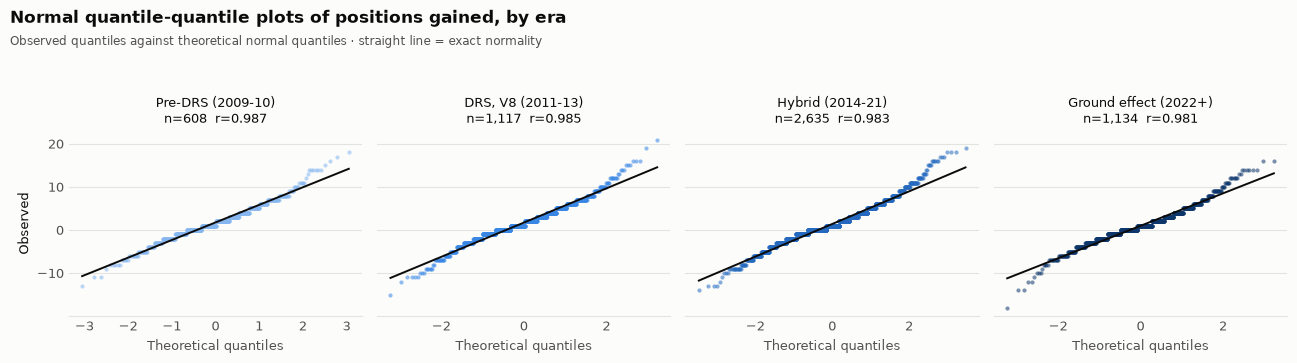

In [36]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.6), facecolor=SURF, sharey=True)
for ax, e, c, lbl in zip(axes, eras, ERA_C, short):
    g = df.loc[df.era == e, "positions_gained"].values
    (osm, osr), (slope, inter, r) = stats.probplot(g, dist="norm")
    ax.scatter(osm, osr, s=9, color=c, alpha=.55, linewidths=0, zorder=2)
    ax.plot(osm, slope*osm + inter, color=INK, lw=1.4, zorder=3)
    ax.set_title(f"{lbl}\nn={g.size:,}  r={r:.3f}", fontsize=9.5, color=INK)
    ax.set_facecolor(SURF); style(ax)
    ax.set_xlabel("Theoretical quantiles", fontsize=9, color=MUTED)
axes[0].set_ylabel("Observed", fontsize=9.5, color=INK)
fig.suptitle("Normal quantile-quantile plots of positions gained, by era",
             fontsize=12, color=INK, x=.006, y=.995, ha="left", va="top",
             fontweight="bold")
fig.text(.006, .925, "Observed quantiles against theoretical normal quantiles · "
         "straight line = exact normality",
         fontsize=8.8, color=MUTED, ha="left", va="top")

fig.tight_layout(rect=[0, 0, 1, .89])
fig.savefig("out/fig3_qq_normality.png", dpi=150, facecolor=SURF)
plt.show()

Welch's ANOVA

In [37]:
def welch_anova(groups):
    """Welch's one-way ANOVA. Verified against pingouin.welch_anova."""
    g = [np.asarray(x, float) for x in groups]
    k = len(g)
    n = np.array([x.size for x in g], float)
    m = np.array([x.mean() for x in g])
    v = np.array([x.var(ddof=1) for x in g])
    w = n / v; sw = w.sum(); mw = (w*m).sum()/sw
    num = (w*(m-mw)**2).sum()/(k-1)
    lam = ((1-w/sw)**2/(n-1)).sum()
    F = num/(1 + (2*(k-2)/(k**2-1))*lam)
    df2 = 1/((3/(k**2-1))*lam)
    return F, k-1, df2, float(stats.f.sf(F, k-1, df2))

Primary Test

In [38]:
print("\n"+"="*78); print("3. PRIMARY TEST  (Task 2 part C4 / Task 3 part F1)"); print("="*78)
print("\n    H0: mean positions gained is equal across all four eras")
print("    H1: at least one era differs")
print(f"    alpha = {ALPHA}\n")

model = smf.ols("positions_gained ~ C(era)", data=df).fit()
atab = sm.stats.anova_lm(model, typ=2)
ss_effect = atab.loc["C(era)", "sum_sq"]; ss_resid = atab.loc["Residual", "sum_sq"]
eta2 = ss_effect/(ss_effect+ss_resid)
F = atab.loc["C(era)", "F"]; p = atab.loc["C(era)", "PR(>F)"]
df1 = int(atab.loc["C(era)", "df"]); df2 = int(atab.loc["Residual", "df"])

print(atab.round(4).to_string())
print(f"\n    One-way ANOVA: F({df1}, {df2}) = {F:.4f},  p = {p:.6g}")
print(f"    eta-squared = {eta2:.5f}  ({eta2*100:.2f}% of variance explained by era)")

F_s, p_s = stats.f_oneway(*groups)
print(f"    scipy cross-check: F = {F_s:.4f}, p = {p_s:.6g}  "
      f"{'(agrees)' if np.isclose(F, F_s) else '(MISMATCH)'}")

Fw, wdf1, wdf2, pw = welch_anova(groups)
print(f"\n    Welch's ANOVA (robust to unequal variance):")
print(f"      F({wdf1}, {wdf2:.1f}) = {Fw:.4f},  p = {pw:.6g}")
primary = "standard" if equal_var else "Welch's"
pF, pp = (F, p) if equal_var else (Fw, pw)
print(f"\n    PRIMARY RESULT ({primary} ANOVA): F = {pF:.4f}, p = {pp:.6g}")
print(f"    CONCLUSION: {'REJECT H0' if pp < ALPHA else 'FAIL TO REJECT H0'} at alpha = {ALPHA}")


3. PRIMARY TEST  (Task 2 part C4 / Task 3 part F1)

    H0: mean positions gained is equal across all four eras
    H1: at least one era differs
    alpha = 0.05

              sum_sq      df       F  PR(>F)
C(era)      391.1180     3.0  8.5224     0.0
Residual  83984.4133  5490.0     NaN     NaN

    One-way ANOVA: F(3, 5490) = 8.5224,  p = 1.20774e-05
    eta-squared = 0.00464  (0.46% of variance explained by era)
    scipy cross-check: F = 8.5224, p = 1.20774e-05  (agrees)

    Welch's ANOVA (robust to unequal variance):
      F(3, 1950.8) = 8.4332,  p = 1.44106e-05

    PRIMARY RESULT (standard ANOVA): F = 8.5224, p = 1.20774e-05
    CONCLUSION: REJECT H0 at alpha = 0.05


Tukey HSD

    A significant ANOVA shows that some era differs, not which. Tukey compares all six pairs whil holing family-wise error at 0.05.

In [39]:
print("\n"+"="*78); print("4. POST-HOC -- TUKEY HSD"); print("="*78)
tuk = pairwise_tukeyhsd(df["positions_gained"], df["era"], alpha=ALPHA)
print(tuk.summary())

# Save it. Part F1 asks for the pairs, and a result that only exists as
# cell output is a result you will be hunting for in six weeks.
tukey_df = pd.DataFrame(tuk.summary().data[1:], columns=tuk.summary().data[0])
tukey_df.to_csv(OUT / "tukey_results.csv", index=False)
print(f"\nwrote {OUT / 'tukey_results.csv'}  "
      f"({int(tukey_df['reject'].astype(str).eq('True').sum())} of "
      f"{len(tukey_df)} pairs differ significantly)")


4. POST-HOC -- TUKEY HSD
                Multiple Comparison of Means - Tukey HSD, FWER=0.05                 
       group1                 group2          meandiff p-adj   lower   upper  reject
------------------------------------------------------------------------------------
1. Pre-DRS (2009-10)     2. DRS, V8 (2011-13)  -0.0338 0.9982 -0.5404  0.4727  False
1. Pre-DRS (2009-10)      3. Hybrid (2014-21)  -0.3576 0.1763 -0.8098  0.0946  False
1. Pre-DRS (2009-10) 4. Ground effect (2022+)  -0.7757 0.0005  -1.281 -0.2705   True
2. DRS, V8 (2011-13)      3. Hybrid (2014-21)  -0.3238 0.0939 -0.6826  0.0351  False
2. DRS, V8 (2011-13) 4. Ground effect (2022+)  -0.7419    0.0 -1.1656 -0.3182   True
 3. Hybrid (2014-21) 4. Ground effect (2022+)  -0.4182  0.014 -0.7751 -0.0612   True
------------------------------------------------------------------------------------

wrote out/tukey_results.csv  (3 of 6 pairs differ significantly)


Supporting Regression

    The interaction term directly tests whether the grid-to-finsh slope differs by era. The per-era slopes are what a team can act on.

    Slope near 1.0 = the grid fully determines the finish.
    Slope near 0 = starting position barely matters.

In [40]:
print("\n"+"="*78); print("5. SUPPORTING MODEL -- REGRESSION WITH ERA INTERACTION"); print("="*78)
inter = smf.ols("positionOrder ~ grid * C(era)", data=df).fit()
itab = sm.stats.anova_lm(inter, typ=2)
irow = [i for i in itab.index if ":" in i][0]
print(f"\n    Interaction term '{irow}':")
print(f"      F = {itab.loc[irow,'F']:.4f}, p = {itab.loc[irow,'PR(>F)']:.6g}")
print("      -> tests directly whether the grid->finish slope differs by era")

print("\n    Per-era slope (finishing places per grid place):")
rows = []
for e in eras:
    sub = df[df.era == e]
    m = smf.ols("positionOrder ~ grid", data=sub).fit()
    lo, hi = m.conf_int().loc["grid"]
    rows.append({"era": e, "slope": m.params["grid"], "ci_low": lo, "ci_high": hi,
                 "r_squared": m.rsquared, "n": len(sub)})
slopes = pd.DataFrame(rows)
print(slopes.round(4).to_string(index=False))


5. SUPPORTING MODEL -- REGRESSION WITH ERA INTERACTION

    Interaction term 'grid:C(era)':
      F = 2.8783, p = 0.0346564
      -> tests directly whether the grid->finish slope differs by era

    Per-era slope (finishing places per grid place):
                     era  slope  ci_low  ci_high  r_squared    n
    1. Pre-DRS (2009-10) 0.6256  0.5844   0.6668     0.5946  608
    2. DRS, V8 (2011-13) 0.6880  0.6584   0.7177     0.6504 1117
     3. Hybrid (2014-21) 0.6472  0.6266   0.6679     0.5887 2635
4. Ground effect (2022+) 0.6757  0.6409   0.7105     0.5620 1134


Robustness

In [41]:
print("\n"+"="*78); print("6. SENSITIVITY -- CLASSIFICATION BOUNDARY"); print("="*78)
print("""
    Including retirements is NOT a useful sensitivity check here. Because
    positions_gained is zero-sum within a race, adding every retired car
    forces each era's mean to exactly 0, and the ANOVA then tests a
    near-identity rather than a hypothesis. Verified below.

    The meaningful robustness question is where the finisher boundary sits:
    lapped cars are classified finishers, but they arguably did not race
    for position. Re-run the test under three definitions.
""")
g_full = [full.loc[full.era == e, "positions_gained"].values for e in eras]
print(f"    (degenerate check) all entries, per-era means: "
      f"{[round(float(x.mean()), 4) for x in g_full]}")

variants = {
    "Finished + lapped (primary)": lambda d: d[d["classified"]],
    "Finished only (strict)":      lambda d: d[d["status"] == "Finished"],
    "Top 10 grid slots only":      lambda d: d[d["classified"] & (d["grid"] <= 10)],
}
rows = []
for label, fn in variants.items():
    sub = fn(full)
    gs = [sub.loc[sub.era == e, "positions_gained"].values for e in eras]
    if min(len(x) for x in gs) < 20:
        continue
    Fv, _, _, pv = welch_anova(gs)
    rows.append({"definition": label, "n": len(sub), "welch_F": round(Fv, 4),
                 "p": float(f"{pv:.6g}"), "reject_H0": pv < ALPHA})
sens = pd.DataFrame(rows)
print(sens.to_string(index=False))
same = sens["reject_H0"].nunique() == 1
print(f"\n    -> conclusion is {'ROBUST' if same else 'SENSITIVE'} to the finisher definition")


6. SENSITIVITY -- CLASSIFICATION BOUNDARY

    Including retirements is NOT a useful sensitivity check here. Because
    positions_gained is zero-sum within a race, adding every retired car
    forces each era's mean to exactly 0, and the ANOVA then tests a
    near-identity rather than a hypothesis. Verified below.

    The meaningful robustness question is where the finisher boundary sits:
    lapped cars are classified finishers, but they arguably did not race
    for position. Re-run the test under three definitions.

    (degenerate check) all entries, per-era means: [0.0, 0.0, -0.0297, -0.1243]
                 definition    n  welch_F        p  reject_H0
Finished + lapped (primary) 5494   8.4332 0.000014       True
     Finished only (strict) 3497   3.0584 0.027391       True
     Top 10 grid slots only 2769   0.6925 0.556729      False

    -> conclusion is SENSITIVE to the finisher definition


Practical Significance

In [42]:
print("\n"+"="*78); print("7. PRACTICAL SIGNIFICANCE  (part F2)"); print("="*78)
first, last = slopes.iloc[0], slopes.iloc[-1]
print(f"    In {first['era']}, one grid place was worth {first['slope']:.3f} finishing places.")
print(f"    In {last['era']},  one grid place is worth {last['slope']:.3f} finishing places.")
chg = (last["slope"] - first["slope"]) / first["slope"] * 100
print(f"    Change: {chg:+.1f}%  (slope closer to 1.0 = grid position more decisive)")
d_mean = desc.loc[eras[0], "mean"] - desc.loc[eras[-1], "mean"]
print(f"\n    Mean positions gained fell from {desc.loc[eras[0],'mean']:.2f} to "
      f"{desc.loc[eras[-1],'mean']:.2f} ({d_mean:.2f} fewer places recovered per race).")
print(f"    Over a 24-race season that is ~{d_mean*24:.0f} places a driver can no")
print(f"    longer recover on Sunday -- the case for moving budget to qualifying.")


7. PRACTICAL SIGNIFICANCE  (part F2)
    In 1. Pre-DRS (2009-10), one grid place was worth 0.626 finishing places.
    In 4. Ground effect (2022+),  one grid place is worth 0.676 finishing places.
    Change: +8.0%  (slope closer to 1.0 = grid position more decisive)

    Mean positions gained fell from 1.76 to 0.98 (0.78 fewer places recovered per race).
    Over a 24-race season that is ~19 places a driver can no
    longer recover on Sunday -- the case for moving budget to qualifying.


Figure 1 - Distribution by Era

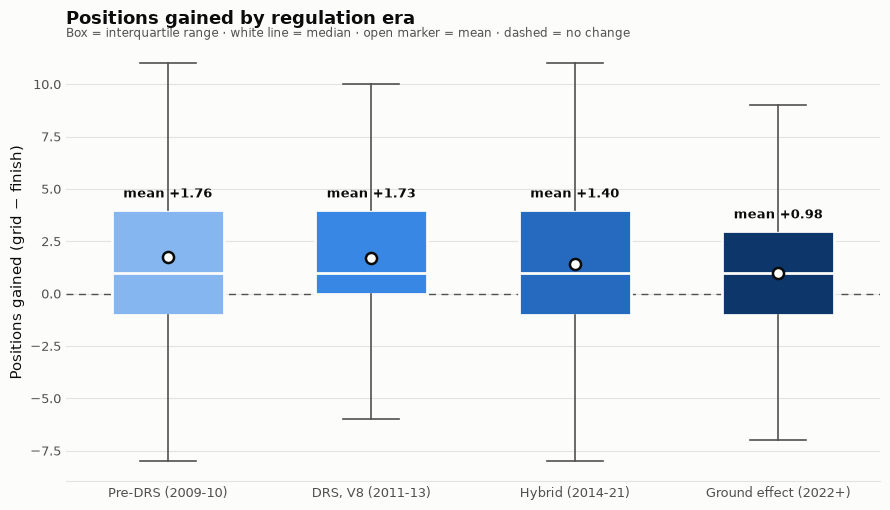

In [43]:
fig, ax = plt.subplots(figsize=(9, 5.2), facecolor=SURF)
ax.set_facecolor(SURF)
bp = ax.boxplot(groups, patch_artist=True, widths=.55, showfliers=False,
                medianprops=dict(color=SURF, lw=2),
                whiskerprops=dict(color=MUTED, lw=1.2),
                capprops=dict(color=MUTED, lw=1.2),
                boxprops=dict(lw=0))
for patch, c in zip(bp["boxes"], ERA_C):
    patch.set_facecolor(c); patch.set_edgecolor(SURF); patch.set_linewidth(2)

for i, g in enumerate(groups, start=1):
    ax.scatter([i], [g.mean()], s=64, color=SURF, edgecolors=INK,
               linewidths=1.8, zorder=6)
    top = np.percentile(g, 75)
    ax.annotate(f"mean {g.mean():+.2f}", (i, top), xytext=(0, 9),
                textcoords="offset points", ha="center",
                fontsize=9.5, color=INK, fontweight="bold")

ax.axhline(0, color=MUTED, lw=1, ls=(0, (5, 4)), zorder=1)
ax.set_xticks(range(1, 5)); ax.set_xticklabels(short, fontsize=9.5, color=INK)
ax.set_ylabel("Positions gained (grid − finish)", fontsize=10.5, color=INK)
ax.set_title("Positions gained by regulation era",
             fontsize=13, color=INK, loc="left", pad=14, fontweight="bold")
ax.text(0, 1.015, "Box = interquartile range · white line = median · "
        "open marker = mean · dashed = no change",
        transform=ax.transAxes, fontsize=8.8, color=MUTED)
style(ax)
fig.tight_layout()
fig.savefig("out/fig1_distribution_by_era.png", dpi=150, facecolor=SURF)
plt.show()

Figure 2 - Grid-to-Finish Slope by Era

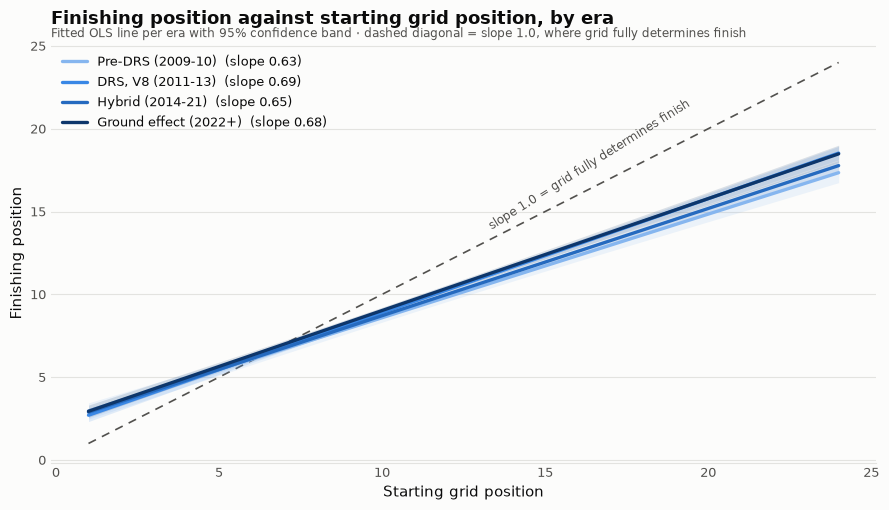

In [44]:
fig, ax = plt.subplots(figsize=(9, 5.2), facecolor=SURF)
ax.set_facecolor(SURF)
xs = np.linspace(1, df["grid"].max(), 50)

for e, c, lbl in zip(eras, ERA_C, short):
    sub = df[df.era == e]
    m = smf.ols("positionOrder ~ grid", data=sub).fit()
    pred = m.get_prediction(pd.DataFrame({"grid": xs})).summary_frame(alpha=.05)
    ax.fill_between(xs, pred["mean_ci_lower"], pred["mean_ci_upper"],
                    color=c, alpha=.14, lw=0, zorder=2)
    ax.plot(xs, pred["mean"], color=c, lw=2.4, zorder=3,
            label=f"{lbl}  (slope {m.params['grid']:.2f})",
            solid_capstyle="round")

ax.plot([1, df["grid"].max()], [1, df["grid"].max()], color=MUTED, lw=1.2,
        ls=(0, (5, 4)), zorder=1)
ax.annotate("slope 1.0 = grid fully determines finish", (df["grid"].max()*.55,
            df["grid"].max()*.58), fontsize=8.8, color=MUTED, rotation=32)
ax.set_xlabel("Starting grid position", fontsize=10.5, color=INK)
ax.set_ylabel("Finishing position", fontsize=10.5, color=INK)
ax.set_title("Finishing position against starting grid position, by era",
             fontsize=13, color=INK, loc="left", pad=14, fontweight="bold")
ax.text(0, 1.015, "Fitted OLS line per era with 95% confidence band · "
        "dashed diagonal = slope 1.0, where grid fully determines finish",
        transform=ax.transAxes, fontsize=8.8, color=MUTED)
ax.legend(frameon=False, fontsize=9, loc="upper left", labelcolor=INK)
style(ax)
fig.tight_layout()
fig.savefig("out/fig2_grid_to_finish_slope.png", dpi=150, facecolor=SURF)
plt.show()

In [45]:
pd.DataFrame([{"test":"Levene W","stat":W,"p":p_lev},
              {"test":"ANOVA F","stat":F,"p":p},
              {"test":"Welch F","stat":Fw,"p":pw},
              {"test":"eta_squared","stat":eta2,"p":np.nan}]).to_csv("out/test_results.csv", index=False)
slopes.to_csv("out/era_slopes.csv", index=False)
sens.to_csv("out/sensitivity.csv", index=False)
desc.to_csv("out/descriptives.csv")
print("\nwrote out/descriptives.csv, out/test_results.csv, out/era_slopes.csv")


wrote out/descriptives.csv, out/test_results.csv, out/era_slopes.csv


Figure 3. Where in the Field the Effect Lives

    Mean positions gained by starting-grid band and era. For a midfield team, this chart answers whether the change is concentrated at the front of the grid or runs through the field.

    NOTE: Reading down a column is meaningless. A driver starting at P1 can only lose places and a driver starting at P18 can only gain. The strong blue-to-red gradient down ech column is the
    mechanical constraint, not a racing insight.

    Read across rows. Within one grid band, compare eras. If the numbers move toward zero from left to right, movement through the field is shrinking.

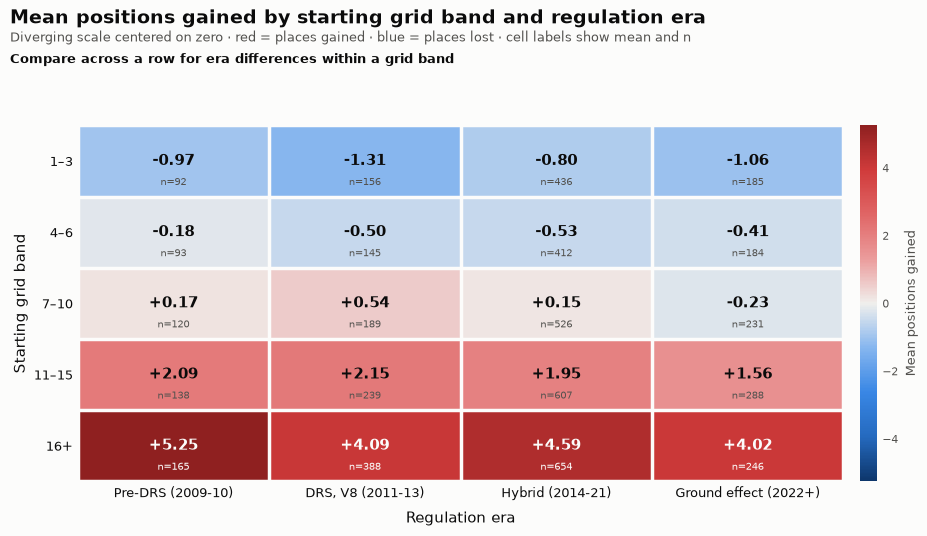

wrote out/fig4_gains_by_grid_band.png

era    1. Pre-DRS (2009-10)  2. DRS, V8 (2011-13)  3. Hybrid (2014-21)  4. Ground effect (2022+)
band                                                                                            
1–3                   -0.97                 -1.31                -0.80                     -1.06
4–6                   -0.18                 -0.50                -0.53                     -0.41
7–10                   0.17                  0.54                 0.15                     -0.23
11–15                  2.09                  2.15                 1.95                      1.56
16+                    5.25                  4.09                 4.59                      4.02


In [46]:
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

# Diverging blue<->red with a neutral gray midpoint: the measure is signed
# (places gained vs lost) and zero is meaningful. Both arms were validated
# as ordinal ramps for monotone lightness and contrast against the surface.
BLUE = ["#0d366b", "#256abf", "#3987e5", "#86b6ef"]     # places LOST
GRAY = "#f0efec"                                        # neutral midpoint
RED  = ["#eb9c9c", "#e06666", "#d03b3b", "#8f2020"]     # places GAINED
cmap = LinearSegmentedColormap.from_list("gained", BLUE + [GRAY] + RED)

BANDS = [(1, 3, "1–3"), (4, 6, "4–6"), (7, 10, "7–10"),
         (11, 15, "11–15"), (16, 30, "16+")]

def band(g):
    for lo, hi, lbl in BANDS:
        if lo <= g <= hi:
            return lbl
    return None

d = df.copy()
d["band"] = d["grid"].apply(band)
d = d.dropna(subset=["band"])

piv = (d.pivot_table(index="band", columns="era",
                     values="positions_gained", aggfunc="mean")
         .reindex([b[2] for b in BANDS]))
counts = (d.pivot_table(index="band", columns="era",
                        values="positions_gained", aggfunc="size")
            .reindex([b[2] for b in BANDS]))

lim = np.nanmax(np.abs(piv.values))
norm = TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim)

fig, ax = plt.subplots(figsize=(9.4, 5.4), facecolor=SURF)
im = ax.imshow(piv.values, cmap=cmap, norm=norm, aspect="auto")

for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        v = piv.values[i, j]
        if np.isnan(v):
            continue
        # white text on the dark ends of either arm, ink text near the middle
        light_text = abs(v) > lim * 0.55
        ax.text(j, i, f"{v:+.2f}", ha="center", va="center", fontsize=11,
                fontweight="bold", color=SURF if light_text else INK)
        ax.text(j, i + .30, f"n={counts.values[i, j]:,.0f}", ha="center",
                va="center", fontsize=7.5,
                color=SURF if light_text else MUTED)

ax.set_xticks(range(len(short)))
ax.set_xticklabels(short, fontsize=9.5, color=INK)
ax.set_yticks(range(len(piv.index)))
ax.set_yticklabels(piv.index, fontsize=9.5, color=INK)
ax.set_ylabel("Starting grid band", fontsize=10.5, color=INK)
ax.set_xlabel("Regulation era", fontsize=10.5, color=INK, labelpad=8)
fig.suptitle("Mean positions gained by starting grid band and regulation era",
             fontsize=13.5, color=INK, x=.012, ha="left", y=.985,
             fontweight="bold")
fig.text(.012, .925,
         "Diverging scale centered on zero · red = places gained · blue = places "
         "lost · cell labels show mean and n",
         fontsize=9, color=MUTED)
fig.text(.012, .885,
         "Compare across a row for era differences within a grid band",
         fontsize=9, color=INK, fontweight="bold")
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_xticks(np.arange(-.5, len(short), 1), minor=True)
ax.set_yticks(np.arange(-.5, len(piv.index), 1), minor=True)
ax.grid(which="minor", color=SURF, lw=2.5)
ax.tick_params(which="minor", length=0)

cb = fig.colorbar(im, ax=ax, pad=.02, fraction=.035)
cb.set_label("Mean positions gained", fontsize=9, color=MUTED)
cb.ax.tick_params(colors=MUTED, labelsize=8, length=0)
cb.outline.set_visible(False)

fig.tight_layout(rect=[0, 0, 1, .86])
fig.savefig("out/fig4_gains_by_grid_band.png", dpi=150, facecolor=SURF)
plt.show()
print("wrote out/fig4_gains_by_grid_band.png")
print()
print(piv.round(2).to_string())

NOTE: Positions gained is near-zero sum within a race, so including every entry pins each era's mean close to zero and the comparison carries almost no information.

In [47]:
full = pd.read_csv(OUT / "analysis_dataset_with_retirements.csv")
groups = [g["positions_gained"].values for _, g in full.groupby("era")]
F, p = stats.f_oneway(*groups)
print(f"retirements included: F = {F:.4f}, p = {p:.4f}  (n = {len(full):,})")
print(full.groupby("era")["positions_gained"].mean().round(4).to_string())

retirements included: F = 0.1522, p = 0.9283  (n = 6,690)
era
1. Pre-DRS (2009-10)        0.0000
2. DRS, V8 (2011-13)        0.0000
3. Hybrid (2014-21)        -0.0297
4. Ground effect (2022+)   -0.1243
